# Predicting Building Damage from the 2015 Gorkha (Nepal) Earthquake

**Module:** CSC61304 Machine Learning and Intelligent Systems, Individual Assignment

**Problem:** Given structural, ownership and location attributes of a building in the earthquake-affected districts of Nepal, predict its **damage grade** (1 = low, 2 = medium, 3 = near-complete destruction). This is a 3-class supervised classification problem.

**Dataset:** Richter's Predictor: Modeling Earthquake Damage (DrivenData), derived from the Nepal Government's post-earthquake building survey (Central Bureau of Statistics / National Planning Commission, 2016). 260,601 buildings, 38 features.

**Notebook outline**
1. Setup
2. Data loading and data dictionary
3. Data quality checks
4. Exploratory data analysis (EDA)
5. Data preprocessing: cleaning, feature engineering, scaling, feature selection, splitting
6. Model implementation (baseline, Logistic Regression, Random Forest, CatBoost)
7. Hyperparameter tuning
8. Results and evaluation
9. Model export for the intelligent system

Figures are saved to `figures/` and tables to `outputs/` so they can be placed directly in the report.

## 1. Setup

In [1]:
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, RandomizedSearchCV, cross_val_score)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score, roc_auc_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_fscore_support, roc_curve)
from catboost import CatBoostClassifier
import joblib
import sklearn, catboost

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# CSV files sit one folder above this notebook by default; override with the DATA_DIR env variable
DATA_DIR = Path(os.environ.get("DATA_DIR", ".."))
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
GRADE_COLORS = {1: "#4C9F70", 2: "#F2A541", 3: "#C8553D"}
GRADE_LABELS = {1: "Grade 1 (low)", 2: "Grade 2 (medium)", 3: "Grade 3 (severe)"}

def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png")
    plt.show()

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| catboost", catboost.__version__)

pandas 3.1.1 | scikit-learn 1.9.1 | catboost 1.2.10


## 2. Data loading

The features and the `damage_grade` label are loaded from a single combined file, `earthquake_train_combined.csv` (the competition's `train_values.csv` and `train_labels.csv` joined on `building_id`). Only the labelled training file is used, because the competition test labels are not public; a hold-out test set is carved out of it in Section 5.

In [2]:
# Single file with the features and the damage_grade label already combined
df = pd.read_csv(DATA_DIR / "earthquake_train_combined.csv")
values = df.drop(columns="damage_grade")   # raw features only, used by the prediction demo in Section 9
print("combined table:", df.shape, "| features:", values.shape)
df.head()

combined table: (260601, 40) | features: (260601, 39)


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,3


### 2.1 Data dictionary

In [3]:
DESCRIPTIONS = {
    "building_id": "Unique building identifier",
    "geo_level_1_id": "Geographic region, level 1 (largest, district-like)",
    "geo_level_2_id": "Geographic region, level 2 (municipality-like)",
    "geo_level_3_id": "Geographic region, level 3 (most specific, ward-like)",
    "count_floors_pre_eq": "Number of floors before the earthquake",
    "age": "Age of the building in years",
    "area_percentage": "Normalised building footprint area",
    "height_percentage": "Normalised building height",
    "land_surface_condition": "Surface condition of the land (encoded)",
    "foundation_type": "Type of foundation (encoded)",
    "roof_type": "Type of roof (encoded)",
    "ground_floor_type": "Type of ground floor (encoded)",
    "other_floor_type": "Type of construction of upper floors (encoded)",
    "position": "Position of the building relative to neighbours (encoded)",
    "plan_configuration": "Building plan shape (encoded)",
    "legal_ownership_status": "Legal ownership status of the land (encoded)",
    "count_families": "Number of families living in the building",
    "has_secondary_use": "Building used for any secondary purpose",
    "damage_grade": "TARGET: damage level 1 (low), 2 (medium), 3 (near-complete destruction)",
}
def describe(col):
    if col in DESCRIPTIONS:
        return DESCRIPTIONS[col]
    if col.startswith("has_superstructure_"):
        return "Superstructure made of " + col.replace("has_superstructure_", "").replace("_", " ")
    if col.startswith("has_secondary_use_"):
        return "Secondary use as " + col.replace("has_secondary_use_", "").replace("_", " ")
    return ""

def feature_group(col):
    if col == "damage_grade": return "Target"
    if col == "building_id": return "Identifier"
    if col.startswith("geo_level"): return "Location"
    if col.startswith("has_superstructure"): return "Superstructure (binary)"
    if col.startswith("has_secondary"): return "Secondary use (binary)"
    if df[col].dtype == object or str(df[col].dtype) in ("str", "string"): return "Categorical"
    return "Numeric"

data_dict = pd.DataFrame({
    "feature": df.columns,
    "group": [feature_group(c) for c in df.columns],
    "dtype": [str(df[c].dtype) for c in df.columns],
    "unique_values": [df[c].nunique() for c in df.columns],
    "description": [describe(c) for c in df.columns],
})
data_dict.to_csv(OUT_DIR / "table_data_dictionary.csv", index=False)
print(data_dict.group.value_counts().to_string())
pd.set_option("display.max_rows", 60, "display.max_colwidth", 80)
data_dict

group
Superstructure (binary)    11
Secondary use (binary)     11
Categorical                 8
Numeric                     5
Location                    3
Identifier                  1
Target                      1


,feature,group,dtype,unique_values,description
0,building_id,Identifier,int64,260601,Unique building identifier
1,geo_level_1_id,Location,int64,31,"Geographic region, level 1 (largest, district-like)"
2,geo_level_2_id,Location,int64,1414,"Geographic region, level 2 (municipality-like)"
3,geo_level_3_id,Location,int64,11595,"Geographic region, level 3 (most specific, ward-like)"
4,count_floors_pre_eq,Numeric,int64,9,Number of floors before the earthquake
5,age,Numeric,int64,42,Age of the building in years
6,area_percentage,Numeric,int64,84,Normalised building footprint area
7,height_percentage,Numeric,int64,27,Normalised building height
8,land_surface_condition,Categorical,str,3,Surface condition of the land (encoded)
9,foundation_type,Categorical,str,5,Type of foundation (encoded)


## 3. Data quality checks

In [4]:
print("Missing values (total):", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate building_id:", df.building_id.duplicated().sum())
df.describe().T[["mean", "std", "min", "50%", "max"]].round(2).head(10)

Missing values (total): 0


Duplicate rows: 0
Duplicate building_id: 0


,mean,std,min,50%,max
building_id,525675.48,304545.00,4.0,525757.0,1052934.0
geo_level_1_id,13.90,8.03,0.0,12.0,30.0
geo_level_2_id,701.07,412.71,0.0,702.0,1427.0
geo_level_3_id,6257.88,3646.37,0.0,6270.0,12567.0
count_floors_pre_eq,2.13,0.73,1.0,2.0,9.0
age,26.54,73.57,0.0,15.0,995.0
area_percentage,8.02,4.39,1.0,7.0,100.0
height_percentage,5.43,1.92,2.0,5.0,32.0
has_superstructure_adobe_mud,0.09,0.28,0.0,0.0,1.0
has_superstructure_mud_mortar_stone,0.76,0.43,0.0,1.0,1.0


Buildings with age == 995: 1390
Next largest age values: [np.int64(190), np.int64(195), np.int64(200), np.int64(995)]

age == 995 by damage grade (share):
damage_grade
1    0.129
2    0.591
3    0.280
Name: proportion, dtype: float64


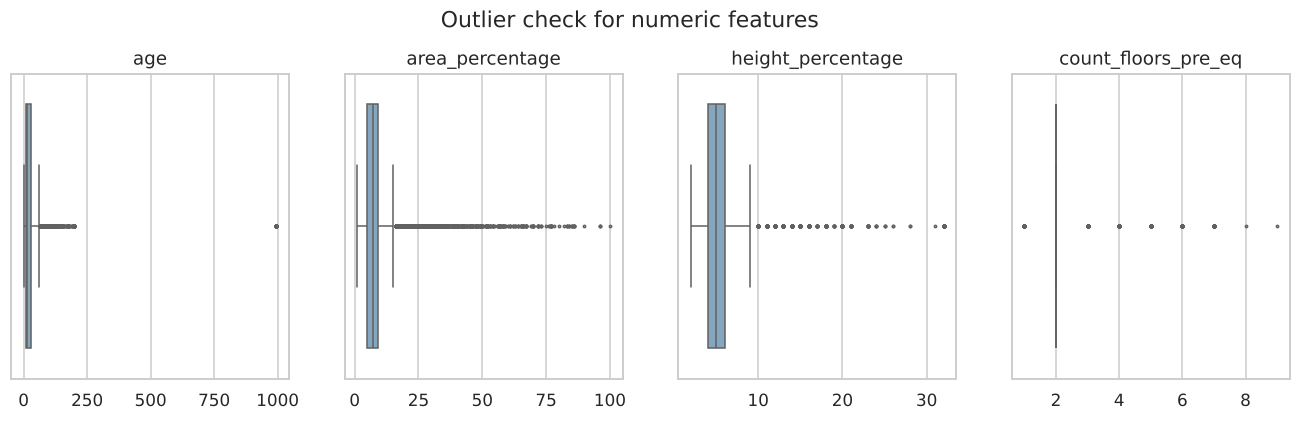

In [5]:
print("Buildings with age == 995:", (df.age == 995).sum())
print("Next largest age values:", sorted(df.age.unique())[-4:])
print("\nage == 995 by damage grade (share):")
print(df.loc[df.age == 995, "damage_grade"].value_counts(normalize=True).sort_index().round(3))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, col in zip(axes, ["age", "area_percentage", "height_percentage", "count_floors_pre_eq"]):
    sns.boxplot(x=df[col], ax=ax, color="#7BA7C9", fliersize=1.5)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Outlier check for numeric features", y=1.04)
save_fig("fig03_outlier_boxplots")

## 4. Exploratory data analysis

### 4.1 Target distribution

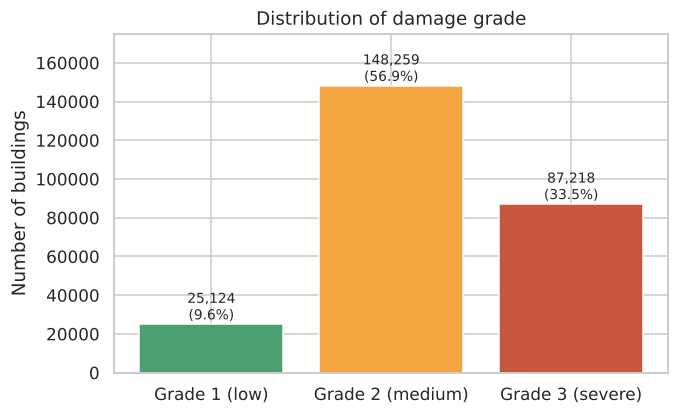

In [6]:
counts = df.damage_grade.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar([GRADE_LABELS[g] for g in counts.index], counts.values,
              color=[GRADE_COLORS[g] for g in counts.index])
for b, c in zip(bars, counts.values):
    ax.annotate(f"{c:,}\n({c / len(df):.1%})", (b.get_x() + b.get_width() / 2, c),
                ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Number of buildings")
ax.set_title("Distribution of damage grade")
ax.set_ylim(0, counts.max() * 1.18)
save_fig("fig04_target_distribution")

### 4.2 Numeric features

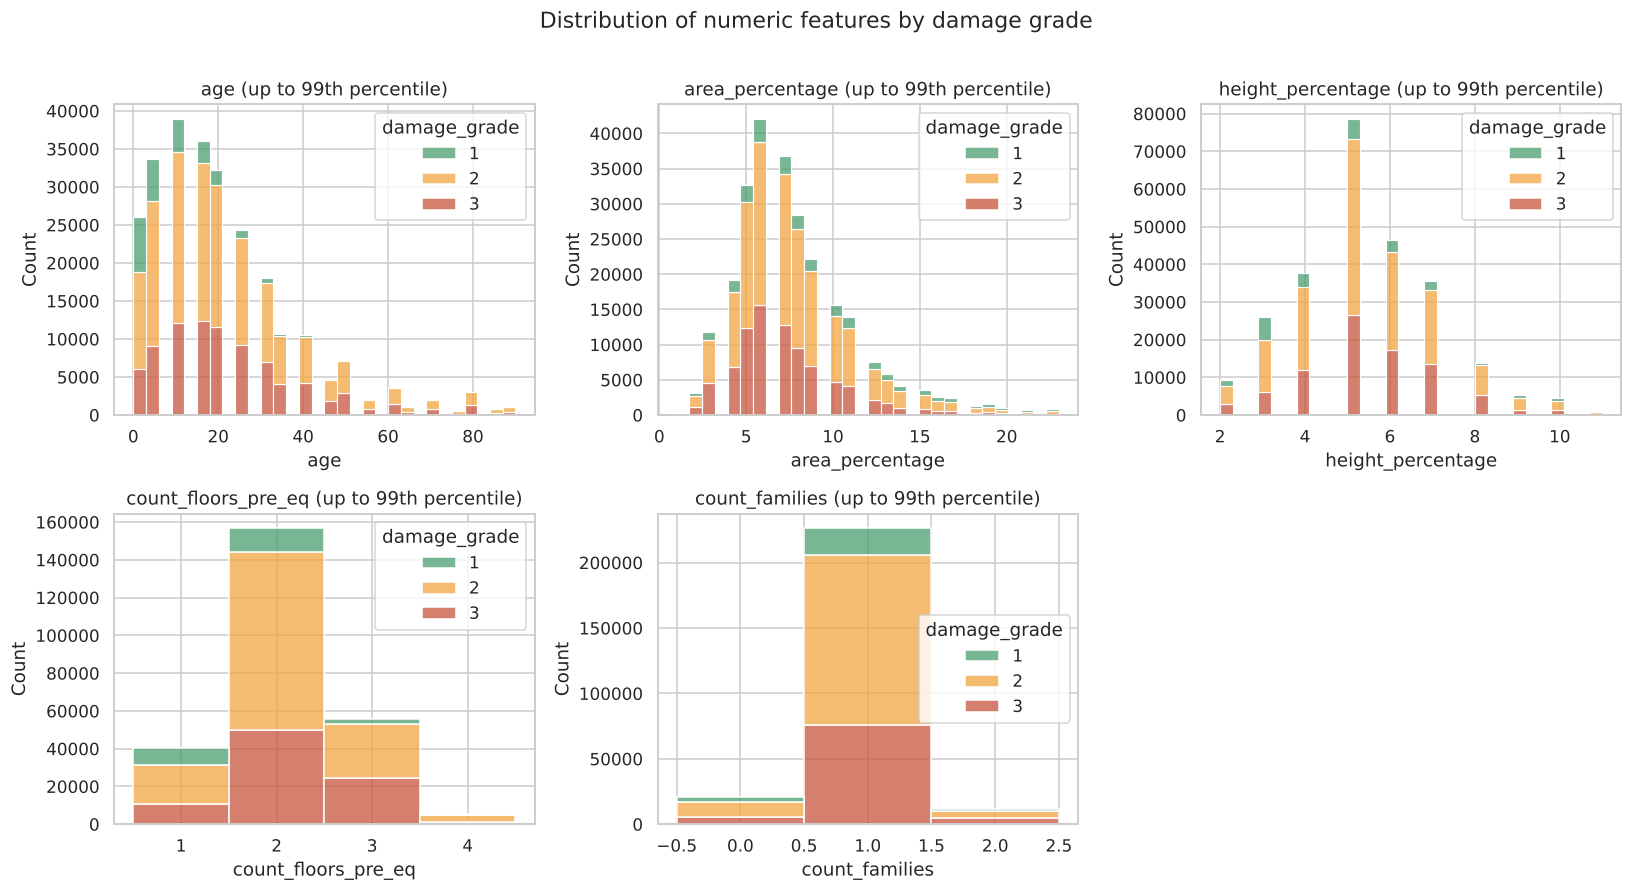

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
plot_cols = ["age", "area_percentage", "height_percentage", "count_floors_pre_eq", "count_families"]
for ax, col in zip(axes.flat, plot_cols):
    data = df[df.age < 995] if col == "age" else df
    upper = data[col].quantile(0.99)
    sns.histplot(data=data[data[col] <= upper], x=col, hue="damage_grade", multiple="stack",
                 palette=GRADE_COLORS, bins=30, ax=ax, discrete=col in ("count_floors_pre_eq", "count_families"))
    ax.set_title(f"{col} (up to 99th percentile)")
axes.flat[-1].axis("off")
fig.suptitle("Distribution of numeric features by damage grade", y=1.01)
plt.tight_layout()
save_fig("fig05_numeric_histograms")

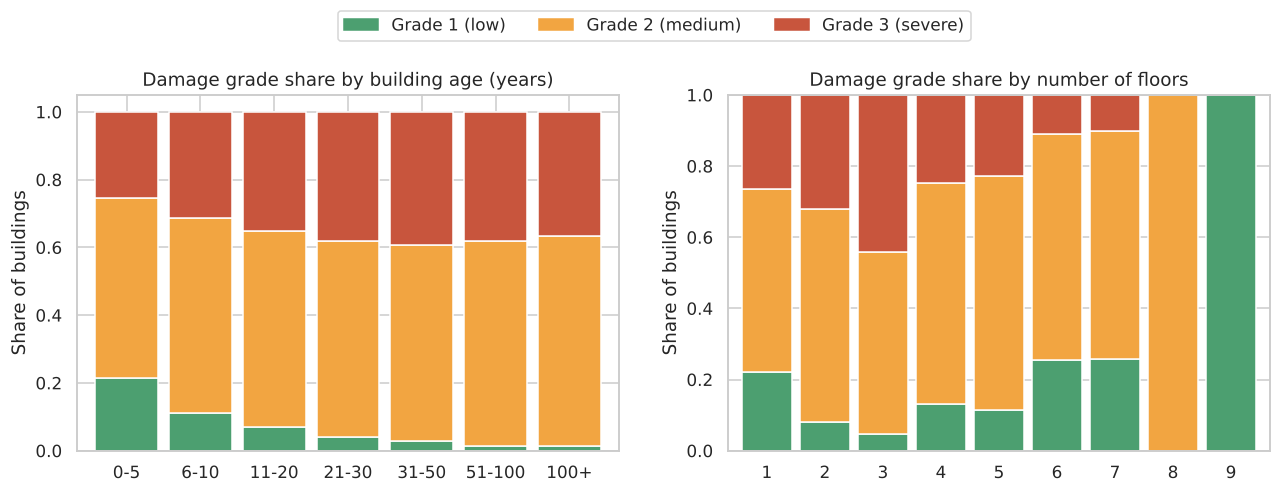

In [8]:
def stacked_share(ax, frame, col, title, order=None):
    share = pd.crosstab(frame[col], frame.damage_grade, normalize="index")
    if order is not None:
        share = share.loc[order]
    share.plot(kind="bar", stacked=True, ax=ax, color=[GRADE_COLORS[g] for g in share.columns],
               width=0.85, legend=False)
    ax.set_title(title); ax.set_ylabel("Share of buildings"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    return share

tmp = df[df.age < 995].copy()
tmp["age_band"] = pd.cut(tmp.age, [-1, 5, 10, 20, 30, 50, 100, 1000],
                         labels=["0-5", "6-10", "11-20", "21-30", "31-50", "51-100", "100+"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
stacked_share(axes[0], tmp, "age_band", "Damage grade share by building age (years)")
stacked_share(axes[1], df, "count_floors_pre_eq", "Damage grade share by number of floors")
handles = [plt.Rectangle((0, 0), 1, 1, color=GRADE_COLORS[g]) for g in (1, 2, 3)]
fig.legend(handles, GRADE_LABELS.values(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08))
save_fig("fig06_age_floors_vs_damage")

### 4.3 Categorical features

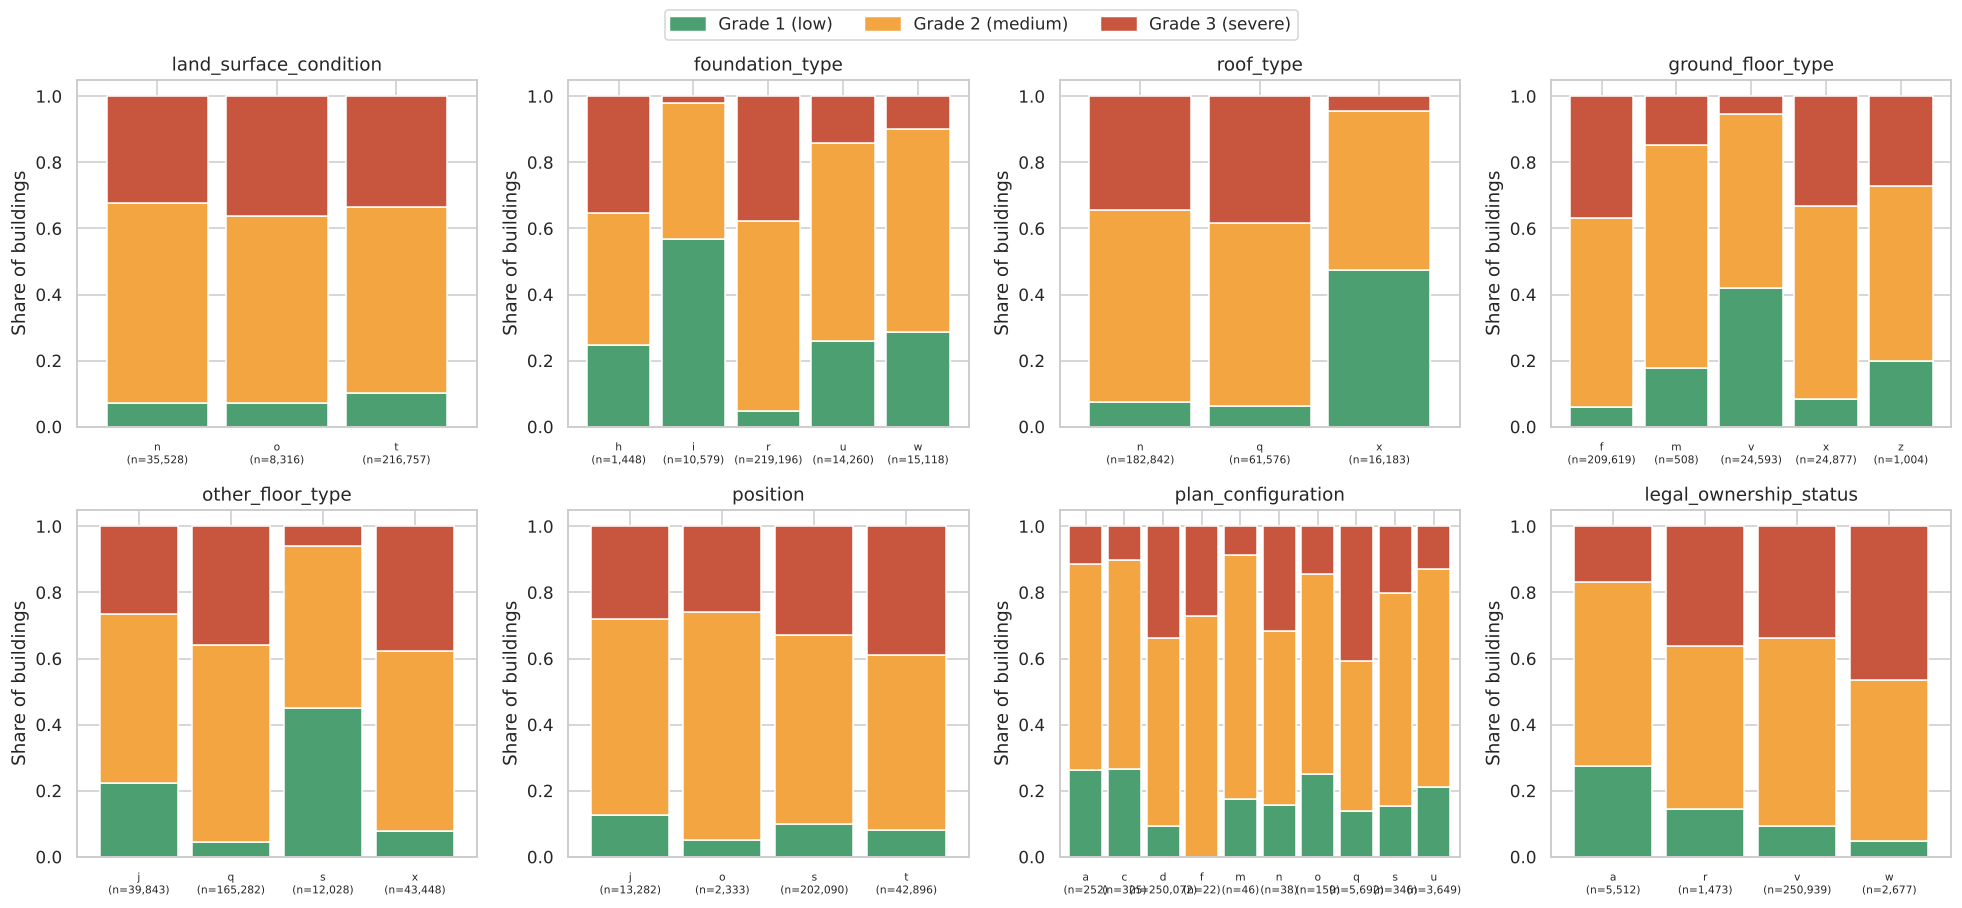

In [9]:
CAT_COLS = ["land_surface_condition", "foundation_type", "roof_type", "ground_floor_type",
            "other_floor_type", "position", "plan_configuration", "legal_ownership_status"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, CAT_COLS):
    share = stacked_share(ax, df, col, col)
    n = df[col].value_counts()
    ax.set_xticklabels([f"{k}\n(n={n[k]:,})" for k in share.index], fontsize=7)
fig.legend(handles, GRADE_LABELS.values(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout()
save_fig("fig07_categorical_vs_damage")

### 4.4 Construction materials (superstructure)

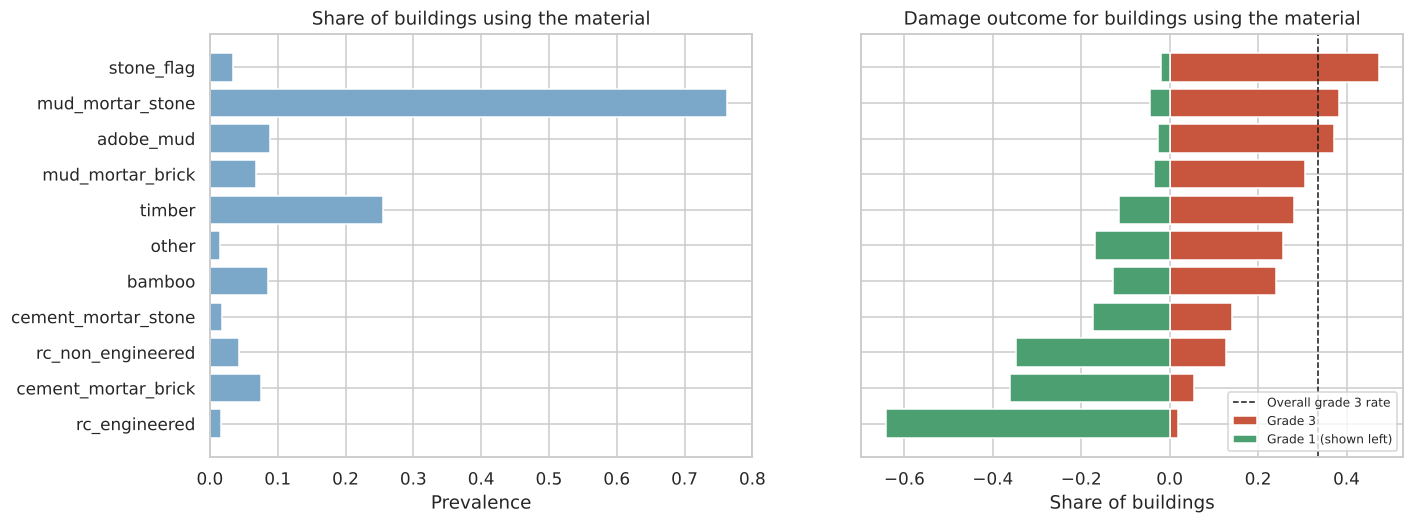

,material,prevalence,share_grade3,share_grade1
9,rc_engineered,0.016,0.018,0.643
5,cement_mortar_brick,0.075,0.056,0.362
8,rc_non_engineered,0.043,0.127,0.348
3,cement_mortar_stone,0.018,0.142,0.174
7,bamboo,0.085,0.240,0.128
10,other,0.015,0.256,0.168
6,timber,0.255,0.280,0.115
4,mud_mortar_brick,0.068,0.306,0.035
0,adobe_mud,0.089,0.372,0.026
1,mud_mortar_stone,0.762,0.382,0.044


In [10]:
SUPER_COLS = [c for c in df.columns if c.startswith("has_superstructure_")]
rows = []
for c in SUPER_COLS:
    sub = df[df[c] == 1]
    rows.append({"material": c.replace("has_superstructure_", ""),
                 "prevalence": sub.shape[0] / len(df),
                 "share_grade3": (sub.damage_grade == 3).mean(),
                 "share_grade1": (sub.damage_grade == 1).mean()})
mat = pd.DataFrame(rows).sort_values("share_grade3")
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
axes[0].barh(mat.material, mat.prevalence, color="#7BA7C9")
axes[0].set_title("Share of buildings using the material"); axes[0].set_xlabel("Prevalence")
axes[1].barh(mat.material, mat.share_grade3, color=GRADE_COLORS[3], label="Grade 3")
axes[1].barh(mat.material, -mat.share_grade1, color=GRADE_COLORS[1], label="Grade 1 (shown left)")
axes[1].axvline((df.damage_grade == 3).mean(), ls="--", c="k", lw=1, label="Overall grade 3 rate")
axes[1].set_title("Damage outcome for buildings using the material"); axes[1].set_xlabel("Share of buildings")
axes[1].legend(loc="lower right", fontsize=8)
save_fig("fig08_superstructure_vs_damage")
mat.round(3)

### 4.5 Geography

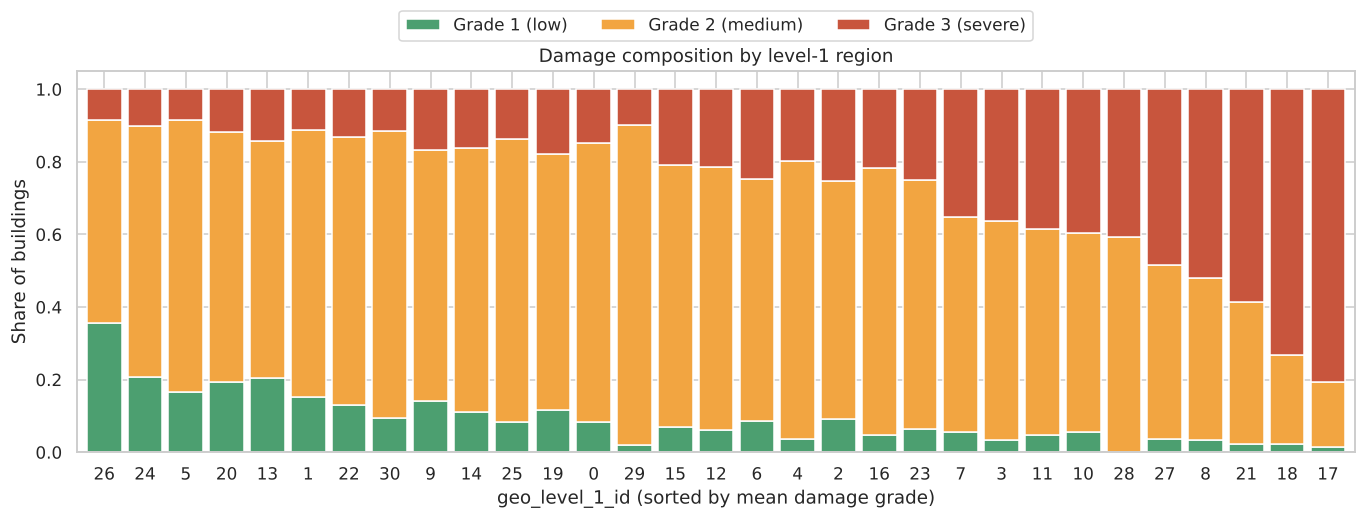

Unique regions per geo level: {'geo_level_1_id': 31, 'geo_level_2_id': 1414, 'geo_level_3_id': 11595}
geo_level_1_id: std of per-region mean grade = 0.244
geo_level_2_id: std of per-region mean grade = 0.345
geo_level_3_id: std of per-region mean grade = 0.404


In [11]:
geo = pd.crosstab(df.geo_level_1_id, df.damage_grade, normalize="index")
geo["mean_grade"] = df.groupby("geo_level_1_id").damage_grade.mean()
geo = geo.sort_values("mean_grade")
fig, ax = plt.subplots(figsize=(15, 4.5))
geo[[1, 2, 3]].plot(kind="bar", stacked=True, ax=ax, width=0.85,
                    color=[GRADE_COLORS[g] for g in (1, 2, 3)])
ax.set_xlabel("geo_level_1_id (sorted by mean damage grade)"); ax.set_ylabel("Share of buildings")
ax.set_title("Damage composition by level-1 region")
ax.legend(GRADE_LABELS.values(), ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.18))
ax.tick_params(axis="x", rotation=0)
save_fig("fig09_geo_level1_vs_damage")

print("Unique regions per geo level:", df[["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]].nunique().to_dict())
for lvl in ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]:
    print(f"{lvl}: std of per-region mean grade = {df.groupby(lvl).damage_grade.mean().std():.3f}")

### 4.6 Correlation with the target

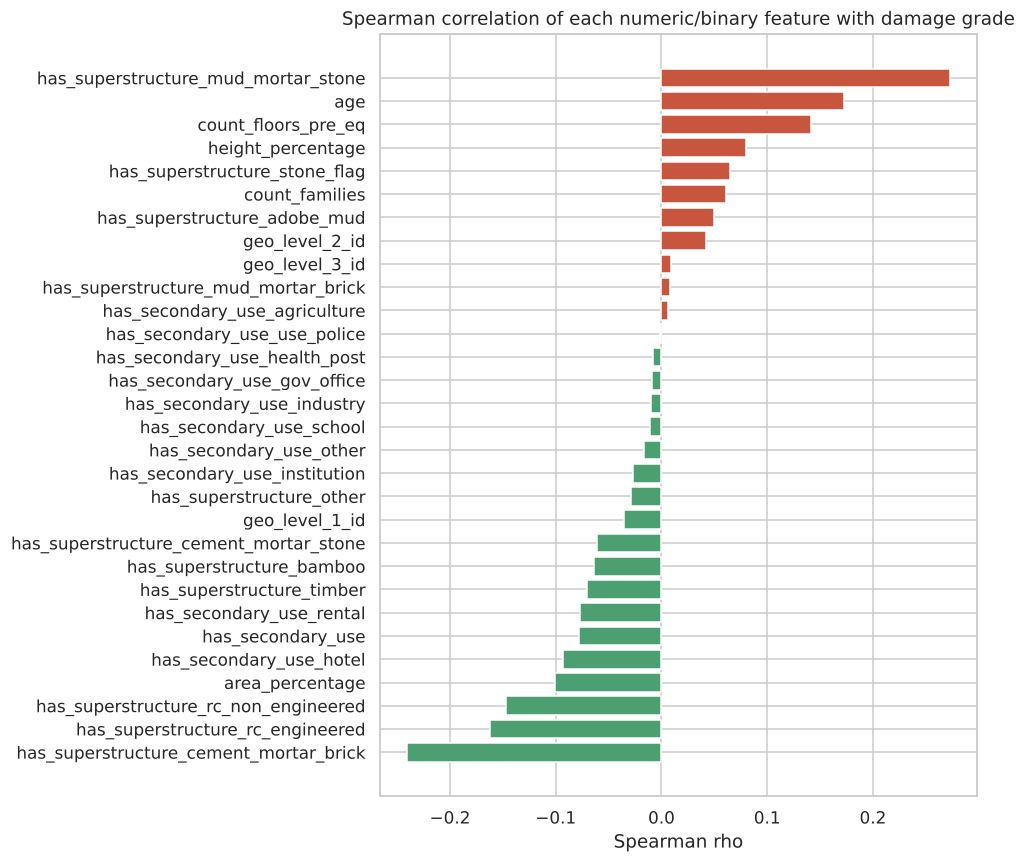

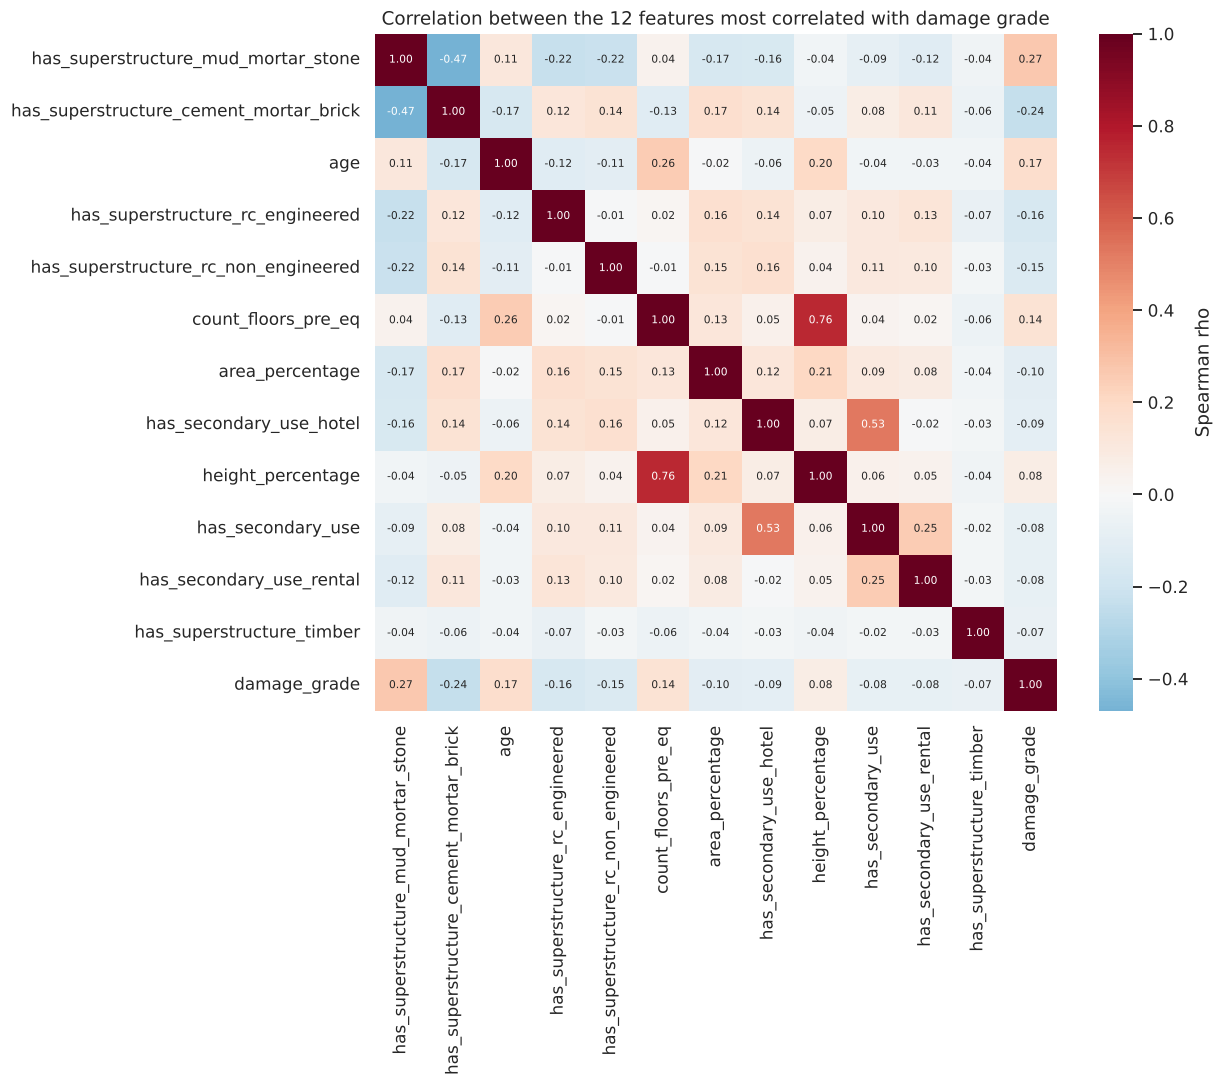

In [12]:
num_bin = df.drop(columns=["building_id"]).select_dtypes("number")
corr = num_bin.corr(method="spearman")
target_corr = corr["damage_grade"].drop("damage_grade").sort_values()
fig, ax = plt.subplots(figsize=(7, 9))
ax.barh(target_corr.index, target_corr.values,
        color=np.where(target_corr.values > 0, GRADE_COLORS[3], GRADE_COLORS[1]))
ax.set_title("Spearman correlation of each numeric/binary feature with damage grade")
ax.set_xlabel("Spearman rho")
save_fig("fig10_target_correlation")

top = target_corr.abs().sort_values(ascending=False).head(12).index.tolist() + ["damage_grade"]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr.loc[top, top], annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
            annot_kws={"size": 7}, cbar_kws={"label": "Spearman rho"})
ax.set_title("Correlation between the 12 features most correlated with damage grade")
save_fig("fig11_correlation_heatmap")

### 4.7 EDA summary

- **Class imbalance:** grade 2 dominates (56.9%), grade 3 is 33.5% and grade 1 only 9.6%, so accuracy alone can hide poor minority-class performance; macro-F1 is reported too.
- **Data quality:** no missing values or duplicates, but `age` contains a placeholder value of 995 in 1,390 buildings (the next largest age is 200). It is flagged and imputed in Section 5.
- **Construction material is the strongest structural signal:** buildings with mud-mortar-stone walls (76% of all buildings) reach grade 3 in 38% of cases, versus 1.8% for engineered reinforced concrete (64% of which are grade 1).
- **Other structural features:** foundation, ground-floor and roof types show clear differences in mean damage (for example roof type `x` averages 1.57 versus 2.27-2.32 for `n`/`q`). Mean damage rises with age up to about 50 years and then flattens.
- **Geography matters a lot:** the spread of mean damage between regions grows with finer geography (standard deviation 0.24 at level 1, 0.35 at level 2, 0.40 at level 3). This is why the location IDs are target-encoded rather than dropped.
- **Redundancy:** some one-hot categories (e.g. most plan configurations) and secondary-use flags are almost constant and are removed by the variance filter.

## 5. Data preprocessing

The steps below follow the rubric's five criteria: **cleaning, feature engineering, scaling, feature selection, and data splitting**.

To avoid data leakage, every step that *learns* from the data (imputation medians, target encoding, scaling statistics, variance filtering) is placed inside a scikit-learn `Pipeline`, so it is fitted on training folds only. Steps that operate on one row at a time (identifier removal, flagging, ratio features) are done up front because they cannot leak information.

### 5.1 Cleaning

In [13]:
def clean(frame):
    out = frame.copy()
    out = out.drop(columns=["building_id"])               # identifier, no predictive meaning
    out["age_is_995"] = (out.age == 995).astype(int)      # 995 is a placeholder value, keep the signal as a flag
    out.loc[out.age == 995, "age"] = np.nan               # then treat the age itself as unknown (imputed later)
    return out

clean_df = clean(df)
print("Shape after cleaning:", clean_df.shape)
print("Ages set to missing:", clean_df.age.isna().sum())

Shape after cleaning: (260601, 40)
Ages set to missing: 1390


### 5.2 Feature engineering

In [14]:
SECOND_COLS = [c for c in df.columns if c.startswith("has_secondary_use_")]

def engineer(frame):
    out = frame.copy()
    out["n_superstructure_materials"] = out[SUPER_COLS].sum(axis=1)
    out["n_secondary_uses"] = out[SECOND_COLS].sum(axis=1)
    out["volume_proxy"] = out.area_percentage * out.height_percentage
    out["height_per_floor"] = out.height_percentage / out.count_floors_pre_eq
    out["area_per_floor"] = out.area_percentage / out.count_floors_pre_eq
    out["is_reinforced_concrete"] = ((out.has_superstructure_rc_engineered == 1) |
                                     (out.has_superstructure_rc_non_engineered == 1)).astype(int)
    out["is_mud_or_adobe_based"] = ((out.has_superstructure_adobe_mud == 1) |
                                    (out.has_superstructure_mud_mortar_stone == 1) |
                                    (out.has_superstructure_mud_mortar_brick == 1)).astype(int)
    return out

full = engineer(clean_df)
NEW_FEATURES = ["n_superstructure_materials", "n_secondary_uses", "volume_proxy",
                "height_per_floor", "area_per_floor", "is_reinforced_concrete", "is_mud_or_adobe_based"]
full[NEW_FEATURES + ["damage_grade"]].groupby("damage_grade").mean().round(3)

,n_superstructure_materials,n_secondary_uses,volume_proxy,height_per_floor,area_per_floor,is_reinforced_concrete,is_mud_or_adobe_based
damage_grade,,,,,,,
1,1.423,0.172,54.917,2.843,6.090,0.257,0.383
2,1.500,0.122,45.190,2.613,4.183,0.049,0.870
3,1.402,0.084,42.507,2.565,3.728,0.017,0.961


Geographic IDs are high-cardinality (31, 1,414 and 11,595 values). One-hot encoding `geo_level_3_id` would create over 11,000 sparse columns, so they are **target-encoded** instead: each ID is replaced by the smoothed probability of each damage grade in that region. `sklearn.preprocessing.TargetEncoder` uses internal cross-fitting during training, so a building's own label never leaks into its encoding.

### 5.3 Data splitting

In [15]:
X = full.drop(columns=["damage_grade"])
y = full["damage_grade"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

split_table = pd.DataFrame({
    "set": ["Train", "Test"],
    "rows": [len(X_train), len(X_test)],
    "grade_1": [(y_train == 1).mean(), (y_test == 1).mean()],
    "grade_2": [(y_train == 2).mean(), (y_test == 2).mean()],
    "grade_3": [(y_train == 3).mean(), (y_test == 3).mean()],
}).round(4)
split_table.to_csv(OUT_DIR / "table_split.csv", index=False)
split_table

,set,rows,grade_1,grade_2,grade_3
0,Train,208480,0.0964,0.5689,0.3347
1,Test,52121,0.0964,0.5689,0.3347


An 80/20 **stratified** split keeps the class proportions identical in both sets. The test set is touched **only once**, in Section 8. Model selection and tuning use stratified cross-validation on the training set.

### 5.4 Scaling, encoding and feature selection pipeline

In [16]:
GEO_COLS = ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]
NUM_COLS = ["count_floors_pre_eq", "age", "area_percentage", "height_percentage", "count_families",
            "volume_proxy", "height_per_floor", "area_per_floor", "n_superstructure_materials", "n_secondary_uses"]
BIN_COLS = SUPER_COLS + ["has_secondary_use"] + SECOND_COLS + ["age_is_995", "is_reinforced_concrete",
                                                                "is_mud_or_adobe_based"]
assert set(GEO_COLS + NUM_COLS + BIN_COLS + CAT_COLS) == set(X.columns)

def make_preprocessor(variance_threshold=0.005):
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    geo = Pipeline([("target_encode", TargetEncoder(target_type="multiclass", random_state=RANDOM_STATE)),
                    ("scale", StandardScaler())])
    categorical = Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
                            ("drop_rare", VarianceThreshold(variance_threshold))])
    binary = Pipeline([("drop_rare", VarianceThreshold(variance_threshold))])
    return ColumnTransformer([("num", numeric, NUM_COLS),
                              ("geo", geo, GEO_COLS),
                              ("cat", categorical, CAT_COLS),
                              ("bin", binary, BIN_COLS)],
                             verbose_feature_names_out=True)

pre = make_preprocessor()
Xt = pre.fit_transform(X_train, y_train)
feature_names = pre.get_feature_names_out()
print("Raw input columns:", X_train.shape[1], "-> model features:", Xt.shape[1])

Raw input columns: 46 -> model features: 67


- **Scaling:** numeric and target-encoded features are standardised (zero mean, unit variance). This matters for Logistic Regression, which is sensitive to feature scale; tree models are unaffected by it.
- **Encoding:** low-cardinality categoricals are one-hot encoded; geographic IDs are target-encoded.
- **Feature selection (filter):** a `VarianceThreshold` removes binary/one-hot columns that are almost always 0 (variance below 0.005, i.e. present in fewer than about 0.5% of buildings), because they carry too little information to learn from.

In [17]:
dropped = []
for name in ["cat", "bin"]:
    sub = pre.named_transformers_[name]
    vt = sub.named_steps["drop_rare"]
    in_names = (sub.named_steps["onehot"].get_feature_names_out(CAT_COLS) if name == "cat"
                else np.array(BIN_COLS))
    dropped += list(in_names[~vt.get_support()])
print(f"Features removed by the variance filter ({len(dropped)}):")
for d in dropped:
    print("  -", d)

Features removed by the variance filter (15):
  - ground_floor_type_m
  - ground_floor_type_z
  - plan_configuration_a
  - plan_configuration_c
  - plan_configuration_f
  - plan_configuration_m
  - plan_configuration_n
  - plan_configuration_o
  - plan_configuration_s
  - has_secondary_use_institution
  - has_secondary_use_school
  - has_secondary_use_industry
  - has_secondary_use_health_post
  - has_secondary_use_gov_office
  - has_secondary_use_use_police


**Feature selection (ranking):** mutual information (MI) between each processed feature and the target, computed on a 50,000-row sample of the training set. This supports the filter above and shows which inputs carry most information before any model is trained.

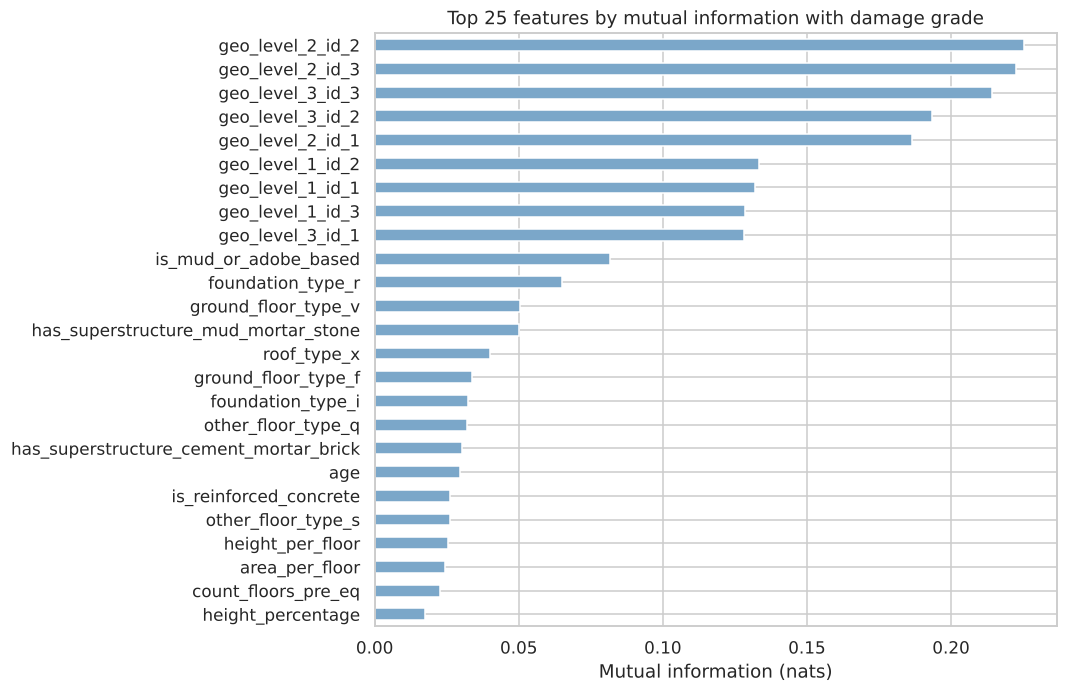

Features with MI below 0.001: 15 of 67


In [18]:
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(Xt), 50_000, replace=False)
mi = mutual_info_classif(Xt[idx], y_train.values[idx], random_state=RANDOM_STATE)
mi_s = pd.Series(mi, index=[n.split("__", 1)[1] for n in feature_names]).sort_values(ascending=False)
mi_s.to_csv(OUT_DIR / "table_mutual_information.csv", header=["mutual_information"])

fig, ax = plt.subplots(figsize=(8, 7))
mi_s.head(25)[::-1].plot(kind="barh", ax=ax, color="#7BA7C9")
ax.set_title("Top 25 features by mutual information with damage grade")
ax.set_xlabel("Mutual information (nats)")
save_fig("fig12_mutual_information")
print("Features with MI below 0.001:", (mi_s < 0.001).sum(), "of", len(mi_s))

## 6. Model implementation

Four models are compared:

| Model | Why it is included |
|---|---|
| **Dummy (majority class)** | Reference floor: any useful model must beat it. |
| **Logistic Regression** (multinomial) | Linear, fast and interpretable baseline; tests whether damage is linearly separable in feature space. |
| **Random Forest** | Bagged ensemble of decision trees; captures non-linear interactions (e.g. material x age x region) and is robust to outliers. |
| **CatBoost** | Gradient-boosted trees with ordered boosting and symmetric trees, which reduce overfitting; strong on tabular data with categorical features and often competitive with tuned LightGBM/XGBoost. |

**Evaluation metric.** The primary metric is **micro-averaged F1**, the official metric of the DrivenData competition, so results are directly comparable with published work. For a single-label multiclass problem micro-F1 equals accuracy. Because grade 1 is only about 10% of buildings, **macro-F1** (unweighted mean of per-class F1) is reported alongside it so that minority-class performance is not hidden.

Each model is wrapped in a pipeline with the preprocessor above. First, every model is trained with default settings and scored by 3-fold stratified cross-validation on the training set.

In [19]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def make_pipeline(model):
    return Pipeline([("pre", make_preprocessor()), ("model", model)])

default_models = {
    "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
    "CatBoost": CatBoostClassifier(loss_function="MultiClass", random_seed=RANDOM_STATE, verbose=0, thread_count=-1, allow_writing_files=False),
}
default_rows = []
for name, model in default_models.items():
    t0 = time.time()
    micro = cross_val_score(make_pipeline(model), X_train, y_train, cv=cv, scoring="f1_micro", n_jobs=1)
    default_rows.append({"model": name, "cv_micro_f1_mean": micro.mean(), "cv_micro_f1_std": micro.std(),
                         "cv_time_s": time.time() - t0})
    print(f"{name:22s} micro-F1 = {micro.mean():.4f} +/- {micro.std():.4f}  ({time.time() - t0:.0f}s)")
default_results = pd.DataFrame(default_rows)
default_results.round(4).to_csv(OUT_DIR / "table_default_cv.csv", index=False)

Dummy (majority)       micro-F1 = 0.5689 +/- 0.0000  (3s)


Logistic Regression    micro-F1 = 0.7325 +/- 0.0012  (74s)


Random Forest          micro-F1 = 0.7408 +/- 0.0006  (27s)


CatBoost               micro-F1 = 0.7430 +/- 0.0011  (71s)


## 7. Hyperparameter tuning

Search strategy:
- **Logistic Regression:** exhaustive `GridSearchCV` over regularisation strength `C` and class weighting (small space, so a grid is affordable).
- **Random Forest** and **CatBoost:** `RandomizedSearchCV`, because their spaces are large and random search finds good regions with far fewer fits than a grid (Bergstra & Bengio, 2012).

All searches use the same 3-fold stratified CV and optimise micro-F1, with macro-F1 also recorded. To keep run time practical, each search runs on a stratified 60,000-row sample of the training set; the best configuration is then refitted on the **full** training set (208,480 rows).

In [20]:
X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=60_000, stratify=y_train,
                                        random_state=RANDOM_STATE)
SCORING = {"micro_f1": "f1_micro", "macro_f1": "f1_macro"}
searches = {}

param_lr = {"model__C": [0.01, 0.1, 1.0, 10.0],
            "model__class_weight": [None, "balanced"]}
searches["Logistic Regression"] = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=2000)), param_lr,
    scoring=SCORING, refit="micro_f1", cv=cv, n_jobs=-1)

param_rf = {"model__n_estimators": [200, 300, 500],
            "model__max_depth": [None, 20, 30, 40],
            "model__min_samples_leaf": [1, 2, 4, 8],
            "model__max_features": ["sqrt", 0.3, 0.5],
            "model__class_weight": [None, "balanced_subsample"]}
searches["Random Forest"] = RandomizedSearchCV(
    make_pipeline(RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE)), param_rf, n_iter=15,
    scoring=SCORING, refit="micro_f1", cv=cv, n_jobs=1, random_state=RANDOM_STATE)

param_cb = {"model__iterations": [300, 500, 800],
            "model__learning_rate": [0.03, 0.06, 0.1, 0.15],
            "model__depth": [4, 6, 8, 10],
            "model__l2_leaf_reg": [1, 3, 5, 10],
            "model__random_strength": [0.5, 1, 2],
            "model__bagging_temperature": [0, 0.5, 1]}
searches["CatBoost"] = RandomizedSearchCV(
    make_pipeline(CatBoostClassifier(loss_function="MultiClass", random_seed=RANDOM_STATE, verbose=0,
                                     thread_count=-1, allow_writing_files=False)),
    param_cb, n_iter=12, scoring=SCORING, refit="micro_f1", cv=cv, n_jobs=1, random_state=RANDOM_STATE)

for name, search in searches.items():
    t0 = time.time()
    search.fit(X_tune, y_tune)
    print(f"{name:20s} best CV micro-F1 = {search.best_score_:.4f}  ({time.time() - t0:.0f}s, "
          f"{len(search.cv_results_['params'])} configurations x 3 folds)")

Logistic Regression  best CV micro-F1 = 0.7187  (21s, 8 configurations x 3 folds)


Random Forest        best CV micro-F1 = 0.7266  (357s, 15 configurations x 3 folds)


CatBoost             best CV micro-F1 = 0.7276  (1000s, 12 configurations x 3 folds)


In [21]:
def tidy_results(search):
    res = pd.DataFrame(search.cv_results_)
    pcols = [c for c in res.columns if c.startswith("param_")]
    out = res[pcols + ["mean_test_micro_f1", "std_test_micro_f1", "mean_test_macro_f1", "mean_fit_time"]].copy()
    out.columns = [c.replace("param_model__", "") for c in out.columns]
    return out.sort_values("mean_test_micro_f1", ascending=False).reset_index(drop=True)

tuning_tables = {name: tidy_results(s) for name, s in searches.items()}
for name, t in tuning_tables.items():
    t.to_csv(OUT_DIR / f"table_tuning_{name.lower().replace(' ', '_')}.csv", index=False)

best_params = pd.DataFrame([
    {"model": name, "best_cv_micro_f1": s.best_score_,
     "best_params": {k.replace("model__", ""): v for k, v in s.best_params_.items()}}
    for name, s in searches.items()])
best_params.to_csv(OUT_DIR / "table_best_params.csv", index=False)
pd.set_option("display.max_colwidth", 200)
best_params

,model,best_cv_micro_f1,best_params
0,Logistic Regression,0.718733,"{'C': 10.0, 'class_weight': None}"
1,Random Forest,0.726633,"{'n_estimators': 500, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 40, 'class_weight': None}"
2,CatBoost,0.727633,"{'random_strength': 2, 'learning_rate': 0.03, 'l2_leaf_reg': 5, 'iterations': 800, 'depth': 10, 'bagging_temperature': 0.5}"


In [22]:
for name, t in tuning_tables.items():
    print(f"\n{name}: top 5 configurations")
    display(t.head(5).round(4))


Logistic Regression: top 5 configurations


,C,class_weight,mean_test_micro_f1,std_test_micro_f1,mean_test_macro_f1,mean_fit_time
0,10.00,NaN,0.7187,0.0045,0.6474,1.6643
1,1.00,NaN,0.7185,0.0047,0.6471,1.5691
2,0.10,NaN,0.7182,0.0046,0.6463,1.2436
3,0.01,NaN,0.7180,0.0044,0.6443,0.9225
4,1.00,balanced,0.6694,0.0044,0.6419,1.7025



Random Forest: top 5 configurations


,n_estimators,min_samples_leaf,max_features,max_depth,class_weight,mean_test_micro_f1,std_test_micro_f1,mean_test_macro_f1,mean_fit_time
0,500,4,sqrt,40,NaN,0.7266,0.0046,0.6592,7.2410
1,200,8,sqrt,20,NaN,0.7265,0.0047,0.6564,2.8614
2,500,2,sqrt,30,NaN,0.7264,0.0045,0.6597,8.2890
3,300,8,sqrt,20,NaN,0.7264,0.0041,0.6563,3.8511
4,200,4,sqrt,20,NaN,0.7264,0.0049,0.6582,3.0486



CatBoost: top 5 configurations


,random_strength,learning_rate,l2_leaf_reg,iterations,depth,bagging_temperature,mean_test_micro_f1,std_test_micro_f1,mean_test_macro_f1,mean_fit_time
0,2.0,0.03,5,800,10,0.5,0.7276,0.0037,0.6660,54.3636
1,1.0,0.10,3,300,8,1.0,0.7274,0.0043,0.6657,7.8684
2,0.5,0.06,10,500,10,0.5,0.7273,0.0043,0.6654,34.4844
3,0.5,0.03,10,300,10,0.5,0.7268,0.0036,0.6618,21.6340
4,2.0,0.10,10,800,6,0.5,0.7263,0.0045,0.6648,7.6073


### 7.1 Tuning visualisations

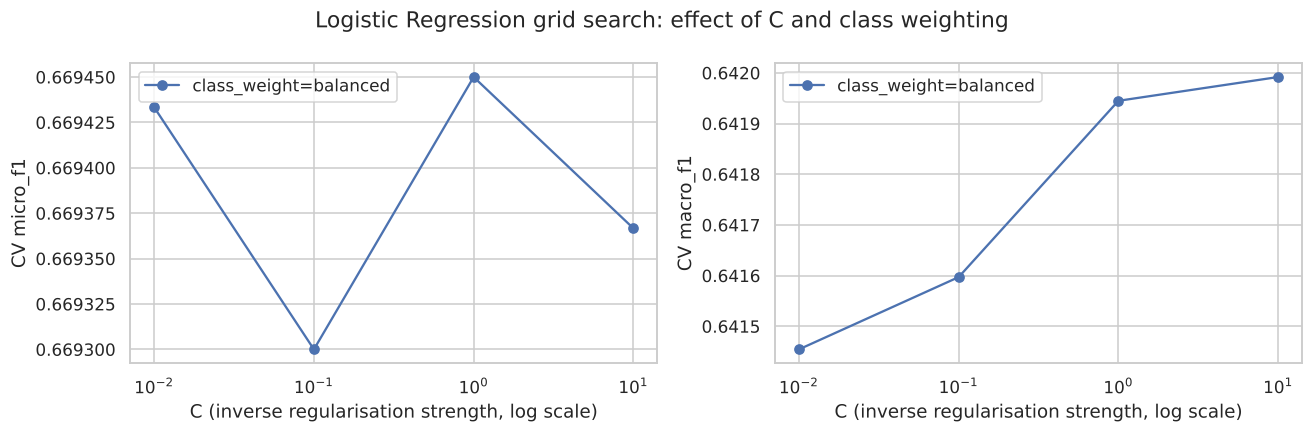

In [23]:
t = tuning_tables["Logistic Regression"].copy()
t["class_weight"] = t["class_weight"].astype(str)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for metric, ax in zip(["mean_test_micro_f1", "mean_test_macro_f1"], axes):
    for cw, g in t.groupby("class_weight"):
        g = g.sort_values("C")
        ax.plot(g["C"].astype(float), g[metric], marker="o", label=f"class_weight={cw}")
    ax.set_xscale("log"); ax.set_xlabel("C (inverse regularisation strength, log scale)")
    ax.set_ylabel(metric.replace("mean_test_", "CV ")); ax.legend()
fig.suptitle("Logistic Regression grid search: effect of C and class weighting")
plt.tight_layout()
save_fig("fig13_tuning_logreg")

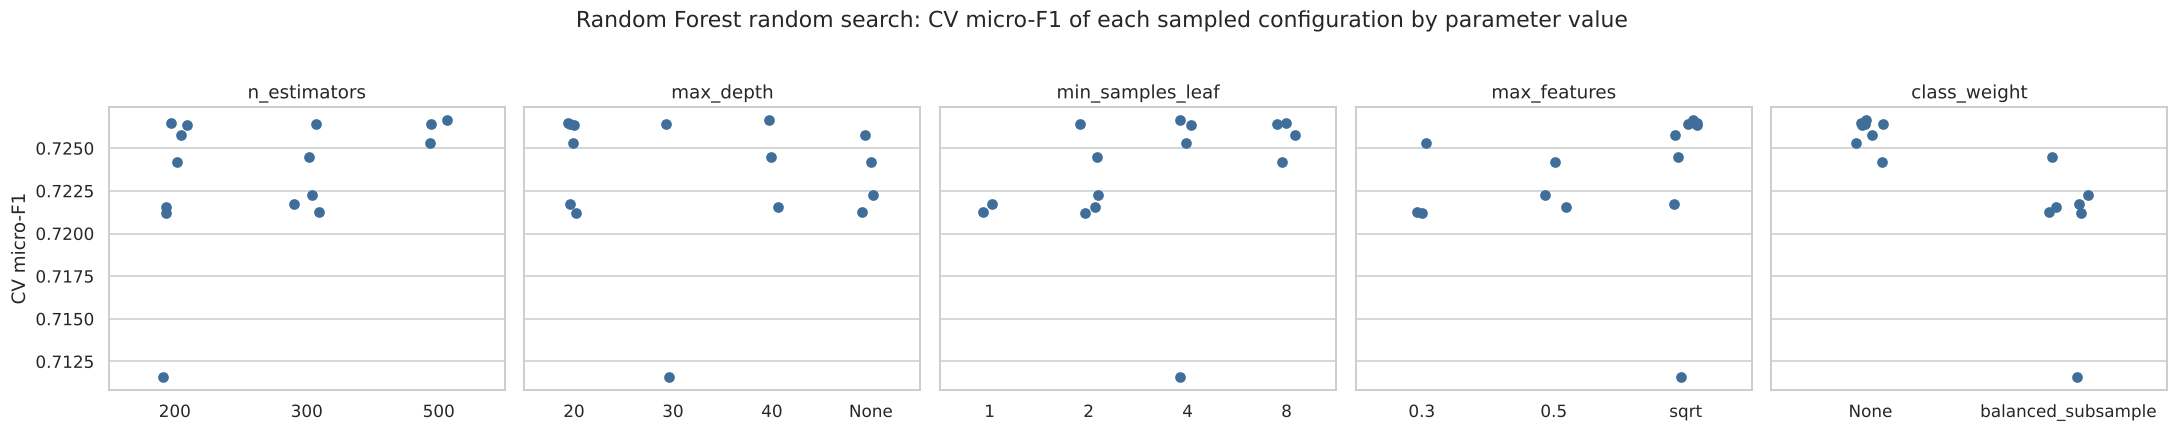

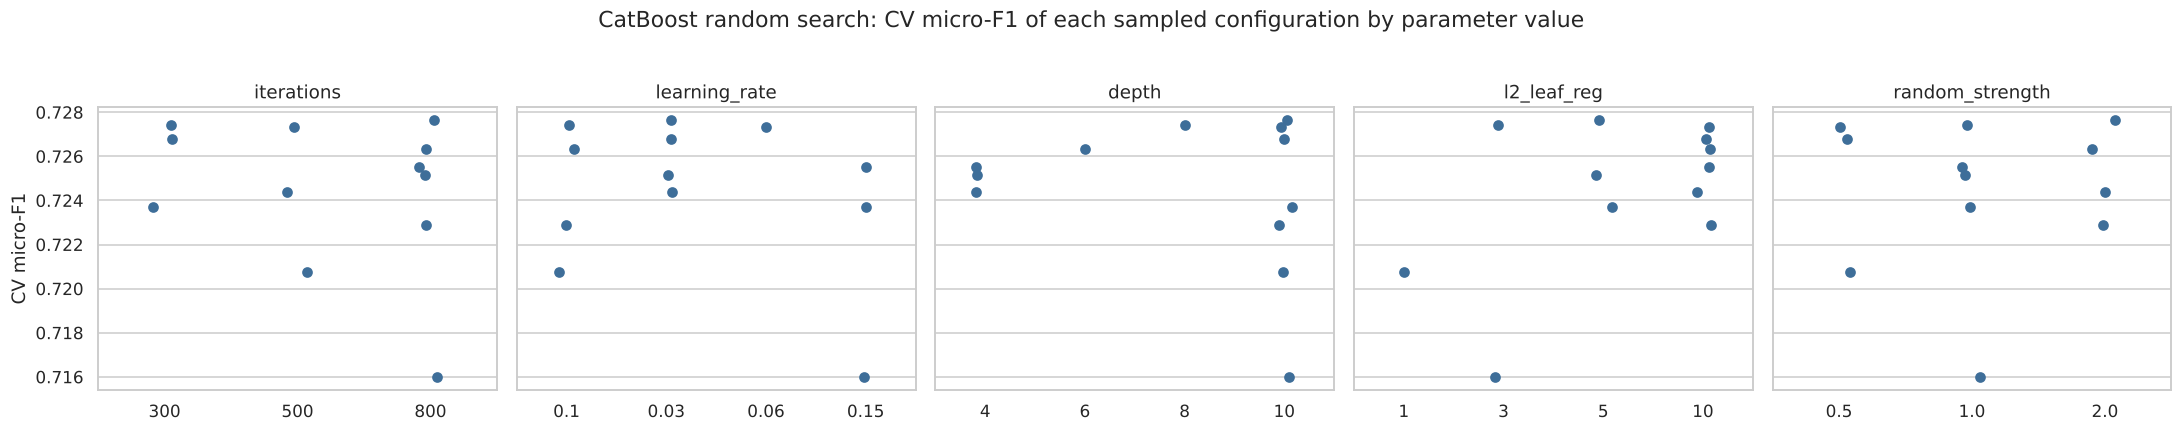

In [24]:
def param_effect_plot(name, params, fname):
    t = tuning_tables[name].copy()
    fig, axes = plt.subplots(1, len(params), figsize=(4 * len(params), 3.8), sharey=True)
    for ax, p in zip(axes, params):
        vals = t[p].astype(object).where(t[p].notna(), "None").astype(str)
        sns.stripplot(x=vals, y=t["mean_test_micro_f1"], ax=ax, size=7, color="#3E6E99",
                      order=sorted(vals.unique(), key=lambda v: (len(v), v)))
        ax.set_title(p); ax.set_xlabel(""); ax.set_ylabel("CV micro-F1")
    fig.suptitle(f"{name} random search: CV micro-F1 of each sampled configuration by parameter value", y=1.03)
    plt.tight_layout()
    save_fig(fname)

param_effect_plot("Random Forest", ["n_estimators", "max_depth", "min_samples_leaf", "max_features", "class_weight"],
                  "fig14_tuning_random_forest")
param_effect_plot("CatBoost", ["iterations", "learning_rate", "depth", "l2_leaf_reg", "random_strength"],
                  "fig15_tuning_catboost")

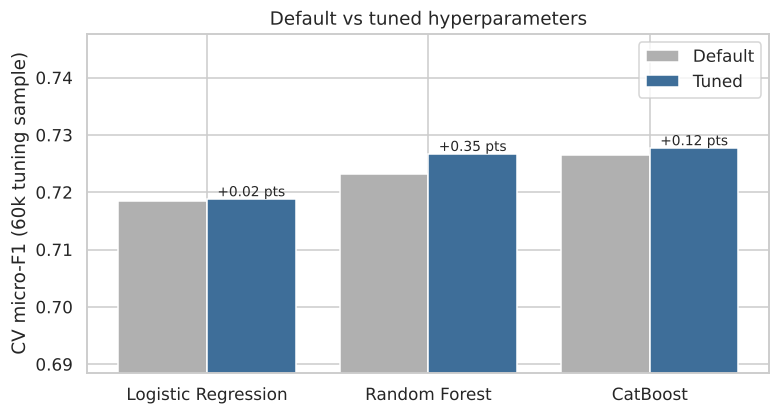

,model,default_cv_micro_f1,tuned_cv_micro_f1,improvement_pts
0,Logistic Regression,0.7185,0.7187,0.0217
1,Random Forest,0.7232,0.7266,0.3467
2,CatBoost,0.7264,0.7276,0.1200


In [25]:
default_vs_tuned = []
for name, search in searches.items():
    d = cross_val_score(make_pipeline(default_models[name]), X_tune, y_tune, cv=cv, scoring="f1_micro").mean()
    default_vs_tuned.append({"model": name, "default_cv_micro_f1": d, "tuned_cv_micro_f1": search.best_score_,
                             "improvement_pts": (search.best_score_ - d) * 100})
default_vs_tuned = pd.DataFrame(default_vs_tuned)
default_vs_tuned.round(4).to_csv(OUT_DIR / "table_default_vs_tuned.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
xx = np.arange(len(default_vs_tuned))
ax.bar(xx - 0.2, default_vs_tuned.default_cv_micro_f1, 0.4, label="Default", color="#B0B0B0")
ax.bar(xx + 0.2, default_vs_tuned.tuned_cv_micro_f1, 0.4, label="Tuned", color="#3E6E99")
for i, r in default_vs_tuned.iterrows():
    ax.annotate(f"+{r.improvement_pts:.2f} pts", (i + 0.2, r.tuned_cv_micro_f1), ha="center", va="bottom", fontsize=9)
ax.set_xticks(xx); ax.set_xticklabels(default_vs_tuned.model)
ax.set_ylim(default_vs_tuned.default_cv_micro_f1.min() - 0.03, default_vs_tuned.tuned_cv_micro_f1.max() + 0.02)
ax.set_ylabel("CV micro-F1 (60k tuning sample)"); ax.set_title("Default vs tuned hyperparameters")
ax.legend()
save_fig("fig16_default_vs_tuned")
default_vs_tuned.round(4)

## 8. Results and evaluation

Each tuned configuration is refitted on the full training set and evaluated **once** on the untouched 20% test set (52,121 buildings).

Metrics reported and why:
- **Micro-F1 / accuracy:** official competition metric; overall share of buildings graded correctly.
- **Macro-F1:** gives each damage grade equal weight, exposing weak minority-class (grade 1) performance.
- **Quadratic weighted Cohen's kappa:** damage grade is *ordinal*, so predicting 1 for a true 3 is worse than predicting 2. QWK penalises errors by their distance.
- **ROC-AUC (one-vs-rest, macro):** threshold-independent ranking quality of the predicted probabilities.
- **Per-class precision/recall/F1** and **confusion matrices:** show where each model fails.

In [26]:
final_models, rows, probas, preds = {}, [], {}, {}
dummy = make_pipeline(DummyClassifier(strategy="most_frequent"))
to_fit = {"Dummy (majority)": dummy, **{n: s.best_estimator_ for n, s in searches.items()}}

for name, pipe in to_fit.items():
    t0 = time.time(); pipe.fit(X_train, y_train); fit_t = time.time() - t0
    t0 = time.time(); p = np.ravel(pipe.predict(X_test)); pr = pipe.predict_proba(X_test); pred_t = time.time() - t0
    final_models[name], preds[name], probas[name] = pipe, p, pr
    rows.append({"model": name,
                 "accuracy / micro_f1": accuracy_score(y_test, p),
                 "macro_f1": f1_score(y_test, p, average="macro"),
                 "weighted_f1": f1_score(y_test, p, average="weighted"),
                 "quadratic_kappa": cohen_kappa_score(y_test, p, weights="quadratic"),
                 "roc_auc_ovr_macro": roc_auc_score(y_test, pr, multi_class="ovr", average="macro"),
                 "f1_grade1": f1_score(y_test, p, labels=[1], average=None)[0],
                 "f1_grade2": f1_score(y_test, p, labels=[2], average=None)[0],
                 "f1_grade3": f1_score(y_test, p, labels=[3], average=None)[0],
                 "train_time_s": fit_t, "predict_time_s": pred_t})
    print(f"{name:22s} fitted in {fit_t:.0f}s")

comparison = pd.DataFrame(rows).set_index("model")
comparison.round(4).to_csv(OUT_DIR / "table_model_comparison_test.csv")
comparison.round(4)

Dummy (majority)       fitted in 1s


Logistic Regression    fitted in 22s


Random Forest          fitted in 50s


CatBoost               fitted in 134s


,accuracy / micro_f1,macro_f1,weighted_f1,quadratic_kappa,roc_auc_ovr_macro,f1_grade1,f1_grade2,f1_grade3,train_time_s,predict_time_s
model,,,,,,,,,,
Dummy (majority),0.5689,0.2417,0.4126,0.0000,0.5000,0.0000,0.7252,0.0000,1.0744,0.1995
Logistic Regression,0.7394,0.6763,0.7330,0.5993,0.8690,0.5497,0.7899,0.6892,21.6463,0.2552
Random Forest,0.7524,0.6997,0.7470,0.6229,0.8822,0.5995,0.7997,0.6998,50.2972,4.2046
CatBoost,0.7499,0.6997,0.7449,0.6220,0.8816,0.6056,0.7971,0.6963,133.9593,0.4498


### 8.1 Metric comparison plot

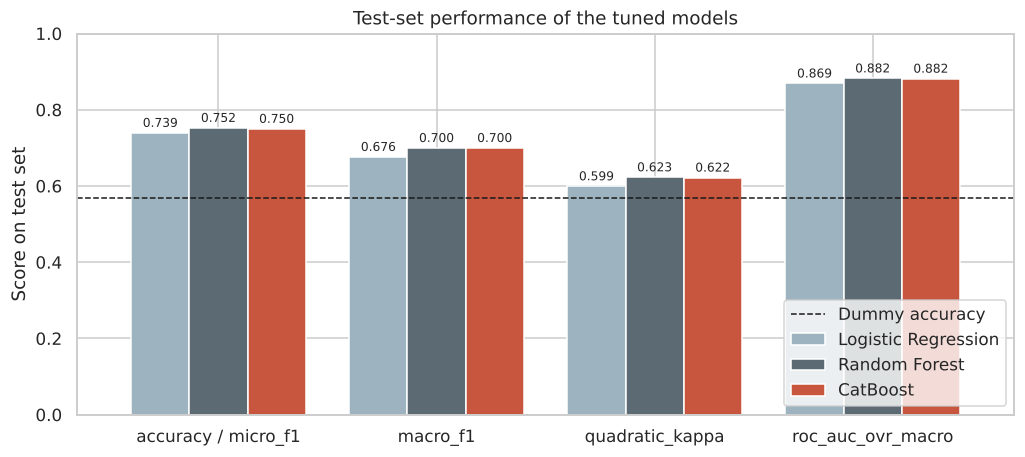

In [27]:
models_plot = [m for m in comparison.index if m != "Dummy (majority)"]
metric_cols = ["accuracy / micro_f1", "macro_f1", "quadratic_kappa", "roc_auc_ovr_macro"]
plot_df = comparison.loc[models_plot, metric_cols]
fig, ax = plt.subplots(figsize=(11, 4.5))
plot_df.T.plot(kind="bar", ax=ax, width=0.8, color=["#9DB4C0", "#5C6B73", "#C8553D"])
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)
ax.axhline(comparison.loc["Dummy (majority)", "accuracy / micro_f1"], ls="--", c="k", lw=1,
           label="Dummy accuracy")
ax.set_ylim(0, 1.0); ax.set_ylabel("Score on test set"); ax.tick_params(axis="x", rotation=0)
ax.set_title("Test-set performance of the tuned models"); ax.legend(loc="lower right")
save_fig("fig17_metric_comparison")

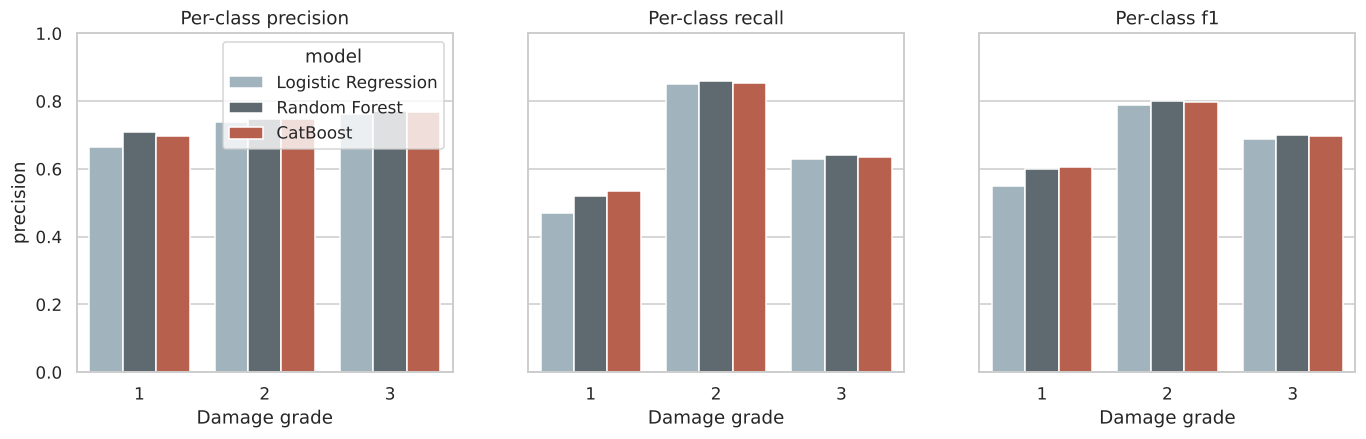

precision               recall                   f1  \
grade                       1      2      3      1      2      3      1   
model                                                                     
CatBoost                0.697  0.748  0.768  0.536  0.853  0.637  0.606   
Logistic Regression     0.665  0.738  0.761  0.469  0.850  0.630  0.550   
Random Forest           0.710  0.749  0.772  0.519  0.858  0.640  0.600   

                                   
grade                    2      3  
model                              
CatBoost             0.797  0.696  
Logistic Regression  0.790  0.689  
Random Forest        0.800  0.700

In [28]:
per_class = []
for name in models_plot:
    p, r, f, s = precision_recall_fscore_support(y_test, preds[name], labels=[1, 2, 3])
    for g, pp, rr, ff in zip([1, 2, 3], p, r, f):
        per_class.append({"model": name, "grade": g, "precision": pp, "recall": rr, "f1": ff})
per_class = pd.DataFrame(per_class)
per_class.round(4).to_csv(OUT_DIR / "table_per_class_metrics.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, metric in zip(axes, ["precision", "recall", "f1"]):
    sns.barplot(data=per_class, x="grade", y=metric, hue="model", ax=ax,
                palette=["#9DB4C0", "#5C6B73", "#C8553D"])
    ax.set_title(f"Per-class {metric}"); ax.set_xlabel("Damage grade"); ax.set_ylim(0, 1)
    if ax is not axes[0]: ax.get_legend().remove()
save_fig("fig18_per_class_metrics")
per_class.pivot(index="model", columns="grade", values=["precision", "recall", "f1"]).round(3)

### 8.2 Confusion matrices

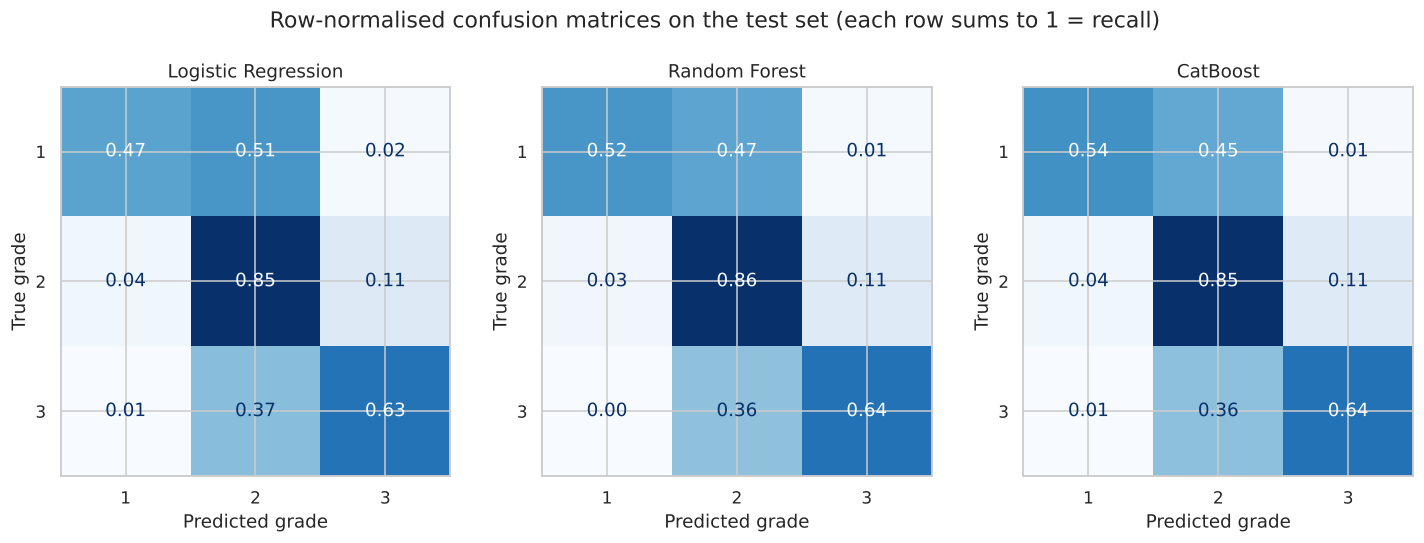

Logistic Regression  errors between non-adjacent grades (1<->3): 181 (1.3% of all errors)
Random Forest        errors between non-adjacent grades (1<->3): 157 (1.2% of all errors)
CatBoost             errors between non-adjacent grades (1<->3): 159 (1.2% of all errors)


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, name in zip(axes, models_plot):
    cm = confusion_matrix(y_test, preds[name], labels=[1, 2, 3], normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=["1", "2", "3"]).plot(ax=ax, cmap="Blues", values_format=".2f",
                                                                     colorbar=False)
    ax.set_title(name); ax.set_xlabel("Predicted grade"); ax.set_ylabel("True grade")
fig.suptitle("Row-normalised confusion matrices on the test set (each row sums to 1 = recall)", y=1.03)
save_fig("fig19_confusion_matrices")

for name in models_plot:
    cm = confusion_matrix(y_test, preds[name], labels=[1, 2, 3])
    far = cm[0, 2] + cm[2, 0]
    print(f"{name:20s} errors between non-adjacent grades (1<->3): {far:,} "
          f"({far / (cm.sum() - np.trace(cm)):.1%} of all errors)")

### 8.3 ROC curves

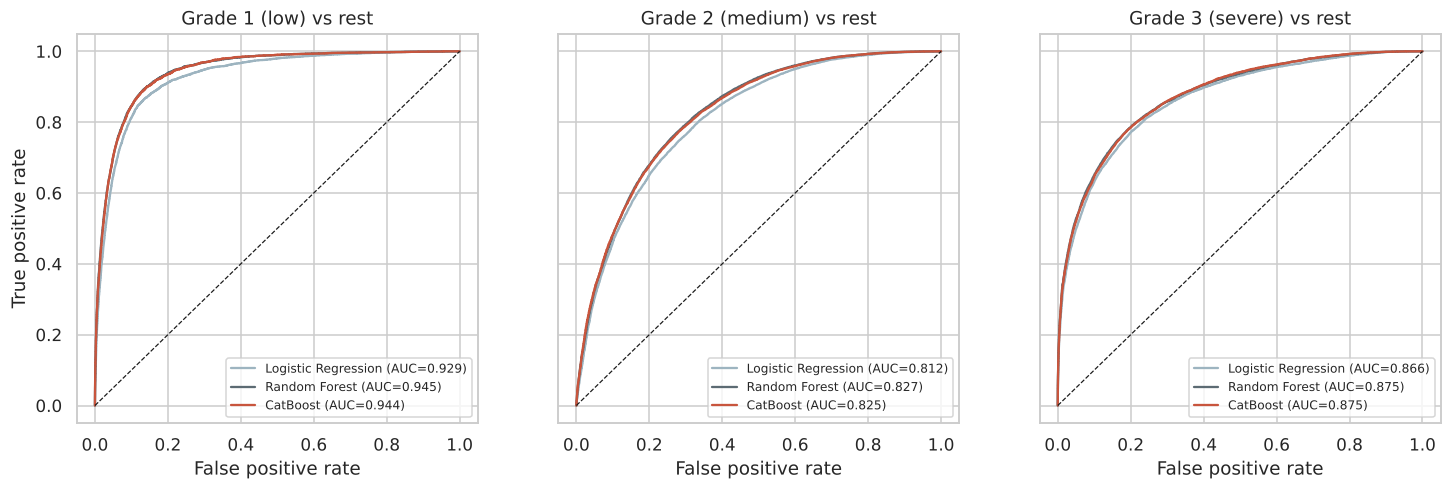

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, g in zip(axes, [1, 2, 3]):
    for name, col in zip(models_plot, ["#9DB4C0", "#5C6B73", "#C8553D"]):
        cls_idx = list(final_models[name].classes_).index(g)
        fpr, tpr, _ = roc_curve(y_test == g, probas[name][:, cls_idx])
        auc = roc_auc_score(y_test == g, probas[name][:, cls_idx])
        ax.plot(fpr, tpr, color=col, label=f"{name} (AUC={auc:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"{GRADE_LABELS[g]} vs rest"); ax.set_xlabel("False positive rate")
    ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("True positive rate")
save_fig("fig20_roc_curves")

### 8.4 Feature importance (best model)

Best model on the test set: Random Forest


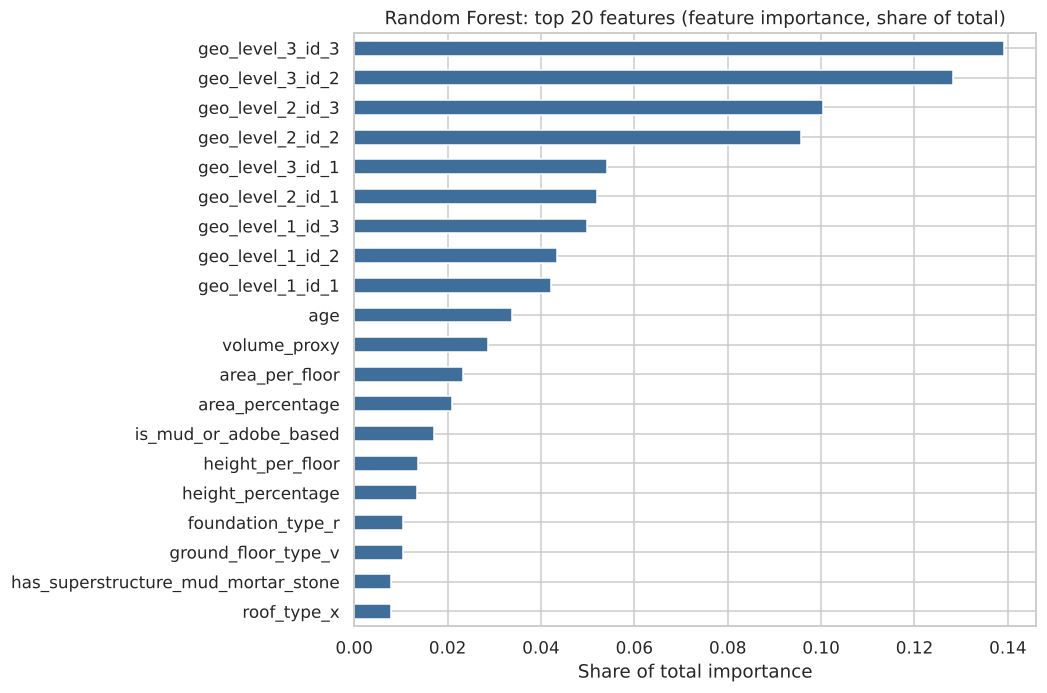

In [31]:
best_name = comparison.drop("Dummy (majority)")["accuracy / micro_f1"].idxmax()
best_pipe = final_models[best_name]
print("Best model on the test set:", best_name)

names = [n.split("__", 1)[1] for n in best_pipe.named_steps["pre"].get_feature_names_out()]
model = best_pipe.named_steps["model"]
imp = pd.Series(np.ravel(model.get_feature_importance()) if hasattr(model, "get_feature_importance") else model.feature_importances_, index=names)
imp_label = "Feature importance"
imp = (imp / imp.sum()).sort_values(ascending=False)
imp.to_csv(OUT_DIR / "table_feature_importance_model.csv", header=["importance_share"])

fig, ax = plt.subplots(figsize=(8, 7))
imp.head(20)[::-1].plot(kind="barh", ax=ax, color="#3E6E99")
ax.set_title(f"{best_name}: top 20 features ({imp_label.lower()}, share of total)")
ax.set_xlabel("Share of total importance")
save_fig("fig21_feature_importance")

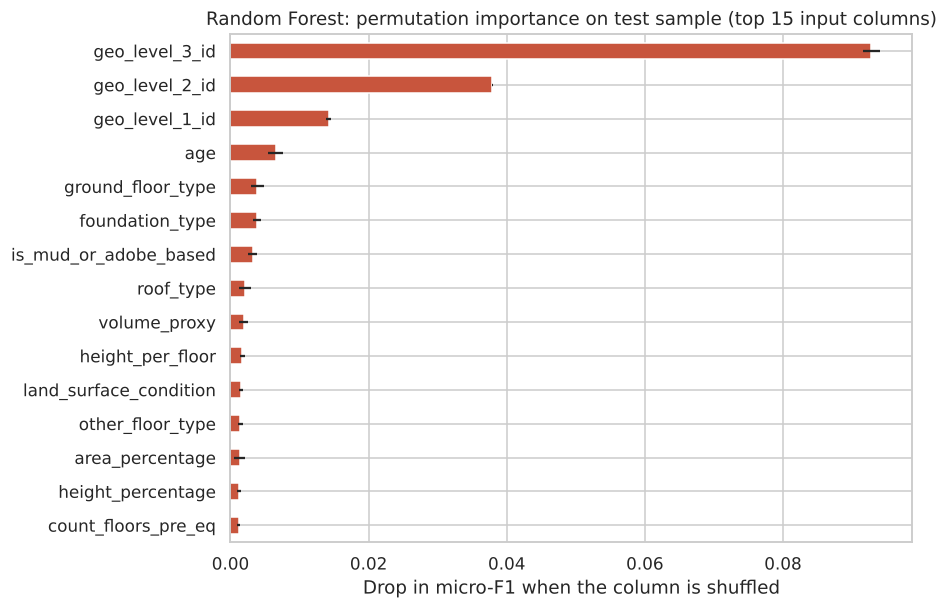

In [32]:
# Permutation importance on raw input columns: how much test micro-F1 drops when a column is shuffled
sample = X_test.sample(15_000, random_state=RANDOM_STATE)
perm = permutation_importance(best_pipe, sample, y_test.loc[sample.index], scoring="f1_micro",
                              n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
perm_s = pd.Series(perm.importances_mean, index=sample.columns).sort_values(ascending=False)
perm_s.to_csv(OUT_DIR / "table_permutation_importance.csv", header=["micro_f1_drop"])
fig, ax = plt.subplots(figsize=(8, 6))
perm_s.head(15)[::-1].plot(kind="barh", ax=ax, xerr=pd.Series(perm.importances_std, index=sample.columns)[perm_s.head(15).index[::-1]],
                           color="#C8553D")
ax.set_title(f"{best_name}: permutation importance on test sample (top 15 input columns)")
ax.set_xlabel("Drop in micro-F1 when the column is shuffled")
save_fig("fig22_permutation_importance")

### 8.5 Statistical comparison of the two best models

In [33]:
ranked = comparison.drop("Dummy (majority)")["accuracy / micro_f1"].sort_values(ascending=False)
a, b = ranked.index[:2]
ca, cb = preds[a] == y_test.values, preds[b] == y_test.values
n01, n10 = int(((~ca) & cb).sum()), int((ca & ~cb).sum())
chi2_stat = (abs(n01 - n10) - 1) ** 2 / (n01 + n10)
p_value = 1 - stats.chi2.cdf(chi2_stat, df=1)
print(f"McNemar test, {a} vs {b}:")
print(f"  only {a} correct: {n10:,} | only {b} correct: {n01:,}")
print(f"  chi2 = {chi2_stat:.2f}, p = {p_value:.2e}")
print("  Difference is statistically significant at 5%" if p_value < 0.05 else "  No significant difference at 5%")

McNemar test, Random Forest vs CatBoost:
  only Random Forest correct: 1,251 | only CatBoost correct: 1,122
  chi2 = 6.90, p = 8.60e-03
  Difference is statistically significant at 5%


## 9. Export the best model for the intelligent system

The full pipeline (cleaning-ready preprocessing + model) is saved so the prediction service in the proposed system architecture can load it and score new building survey records.

In [34]:
joblib.dump(best_pipe, OUT_DIR / "best_model_pipeline.joblib", compress=3)

def predict_damage(records: pd.DataFrame, pipeline=best_pipe):
    # Score raw survey records: apply the same row-wise cleaning and feature engineering, then the pipeline
    feats = engineer(clean(records))
    proba = pipeline.predict_proba(feats)
    out = pd.DataFrame(proba, columns=[f"p_grade_{c}" for c in pipeline.classes_], index=records.index)
    out["predicted_grade"] = pipeline.classes_[proba.argmax(axis=1)]
    out["confidence"] = proba.max(axis=1)
    return out

demo = values.loc[X_test.index[:5]]
demo_out = predict_damage(demo).assign(true_grade=y_test.loc[demo.index].values)
demo_out.round(3)

,p_grade_1,p_grade_2,p_grade_3,predicted_grade,confidence,true_grade
124536,0.027,0.541,0.432,2,0.541,3
112152,0.053,0.643,0.304,2,0.643,2
93613,0.584,0.295,0.121,1,0.584,2
204895,0.039,0.751,0.210,2,0.751,2
37356,0.001,0.127,0.872,3,0.872,3


In [35]:
print("Saved figures:"); print("\n".join(sorted(p.name for p in FIG_DIR.glob("*.png"))))
print("\nSaved tables/models:"); print("\n".join(sorted(p.name for p in OUT_DIR.iterdir())))

Saved figures:
fig03_outlier_boxplots.png
fig04_target_distribution.png
fig05_numeric_histograms.png
fig06_age_floors_vs_damage.png
fig07_categorical_vs_damage.png
fig08_superstructure_vs_damage.png
fig09_geo_level1_vs_damage.png
fig10_target_correlation.png
fig11_correlation_heatmap.png
fig12_mutual_information.png
fig13_tuning_logreg.png
fig14_tuning_random_forest.png
fig15_tuning_catboost.png
fig16_default_vs_tuned.png
fig17_metric_comparison.png
fig18_per_class_metrics.png
fig19_confusion_matrices.png
fig20_roc_curves.png
fig21_feature_importance.png
fig22_permutation_importance.png

Saved tables/models:
best_model_pipeline.joblib
table_best_params.csv
table_data_dictionary.csv
table_default_cv.csv
table_default_vs_tuned.csv
table_feature_importance_model.csv
table_model_comparison_test.csv
table_mutual_information.csv
table_per_class_metrics.csv
table_permutation_importance.csv
table_split.csv
table_tuning_catboost.csv
table_tuning_logistic_regression.csv
table_tuning_random_fores